# Grocery Sales Forecasting
Time-series forecasting of daily store-level sales for the Kaggle *Store Sales* (Favorita) dataset. See the README for the summary of results.

## Setup
Imports and data loading. The `helper` module (data import, holiday preprocessing, RMSLE metric, submission writer) was provided by the course and is not included.

In [1]:
import json
import numpy as np
import pandas as pd
import os
from pathlib import Path
from tqdm.notebook import tqdm
import statsmodels.api as sm # PACF, ACF
from typing import Tuple, List

# Viz:
import matplotlib.pyplot as plt
import seaborn as sns

Path("answers").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())
print("Local answers directory:", Path("answers").resolve())


Working directory: .
Local answers directory: ./answers


In [2]:
import importlib
from pathlib import Path
import helper

importlib.reload(helper)

print("Helper imported from:", Path(helper.__file__).resolve())
print("Output directory:", helper.OUTPUT_DIR.resolve())
try:
    print("Resolved data directory:", helper.resolve_data_dir().resolve())
except FileNotFoundError as err:
    print(err)


Helper imported from: ./helper.py
Output directory: ./answers
Resolved data directory: ./data/store-sales-time-series-forecasting


In [3]:
import gc

def cleanup():
    gc.collect()

In [4]:
train, test, stores, transactions, oil, holidays = helper.data_import()
holidays, regional, national, local, events, work_day, _, _, _ = helper.preprocess_holidays(holidays)

## 1. Data integration & exploratory analysis
Join store transactions onto the sales data, check how transactions relate to sales (Spearman correlation, OLS fit), and look at seasonality by month and day of week.

In [5]:
# 1. Create merged_df by left-joining transactions to the combined train+test dataframe.
combined = pd.concat([train, test], ignore_index=True)
merged_df = combined.merge(transactions, on=["date", "store_nbr"], how="left")

In [7]:
# Using q1a_df, create q1b_input_df with the columns needed for the correlation calculation.
# Remove rows with missing values if needed.
q1b_input_df = q1a_df[["sales", "transactions"]].dropna()

In [9]:
# Using q1a_df, create q2_df with the variables needed for OLS.
# Remove rows with missing values if needed.

q2_df = q1a_df[["transactions", "sales"]].dropna()


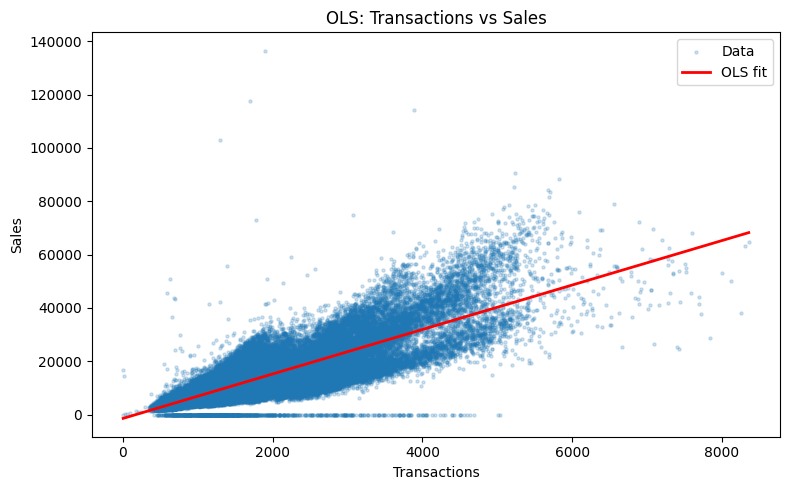

In [11]:
import numpy as np

x_line = np.linspace(q2_df["transactions"].min(), q2_df["transactions"].max(), 200)
y_line = intercept + slope * x_line

plt.figure(figsize=(8, 5))
plt.scatter(q2_df["transactions"], q2_df["sales"], alpha=0.2, s=5, label="Data")
plt.plot(x_line, y_line, color="red", linewidth=2, label="OLS fit")
plt.xlabel("Transactions")
plt.ylabel("Sales")
plt.title("OLS: Transactions vs Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Using merged_df or transactions, create q3a_source_df for the Q3A visualization.

q3a_source_df = q1a_df[["date", "store_nbr", "transactions"]].dropna()


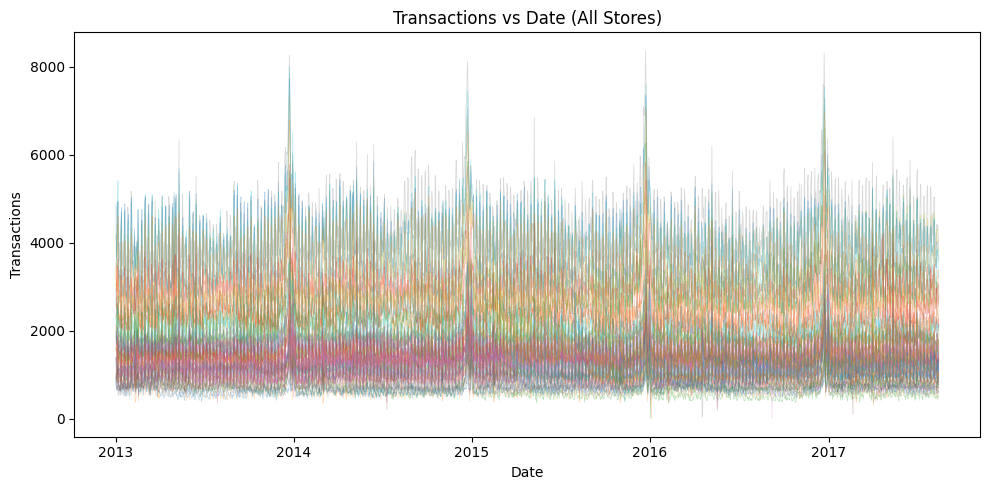

In [14]:
plt.figure(figsize=(10, 5))
for store in q3a_df["store_nbr"].unique():
    store_data = q3a_df[q3a_df["store_nbr"] == store]
    plt.plot(store_data["date"], store_data["transactions"], alpha=0.3, linewidth=0.5)

plt.xlabel("Date")
plt.ylabel("Transactions")
plt.title("Transactions vs Date (All Stores)")
plt.tight_layout()
plt.show()

In [15]:
# Using merged_df or transactions, create q3b_source_df for the monthly summary.

q3b_source_df = q3a_source_df.copy()
q3b_source_df["month"] = q3b_source_df["date"].dt.month_name()


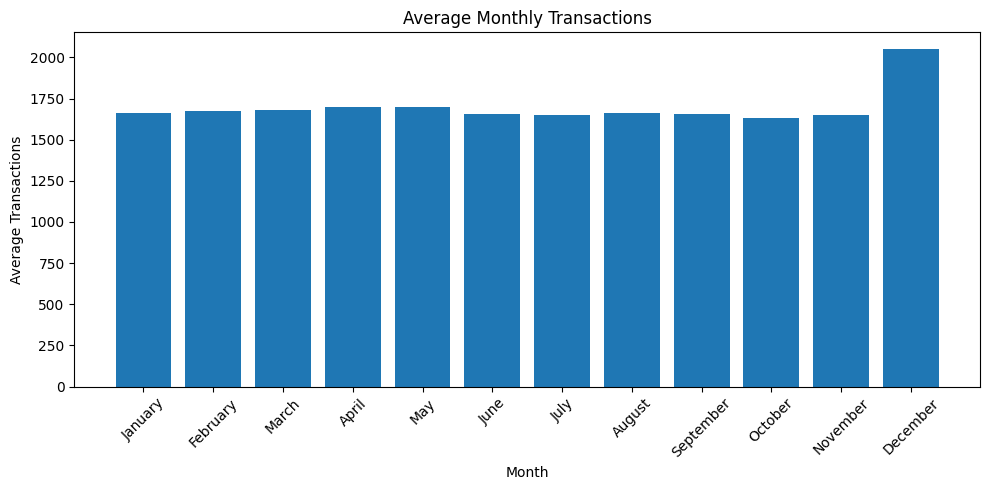

In [17]:
plt.figure(figsize=(10, 5))
plt.bar(q3b_df["month"], q3b_df["avg_transactions"])
plt.xlabel("Month")
plt.ylabel("Average Transactions")
plt.title("Average Monthly Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# Using merged_df or transactions, create q3c_source_df for the day-of-week summary.

q3c_source_df = q3a_source_df.copy()
q3c_source_df["day_of_week"] = q3c_source_df["date"].dt.day_name()


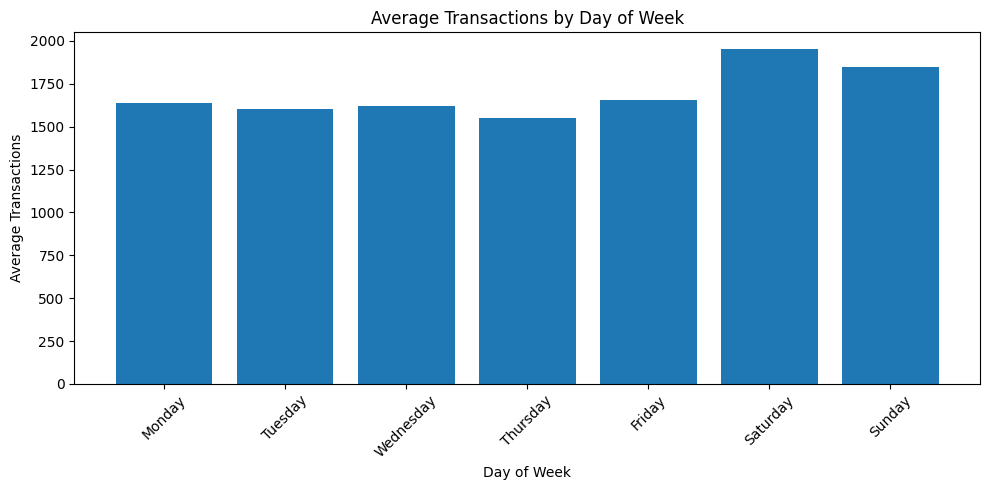

In [20]:
plt.figure(figsize=(10, 5))
plt.bar(q3c_df["day_of_week"], q3c_df["avg_transactions"])
plt.xlabel("Day of Week")
plt.ylabel("Average Transactions")
plt.title("Average Transactions by Day of Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Oil price feature
Oil prices have gaps on weekends and holidays, so the series is linearly interpolated, joined onto the sales data, and checked for correlation with sales overall and by product family.

In [21]:
# 1. Resample oil to daily frequency.
# 2. Replace 0 values in dcoilwtico with NaN.
# 3. Create dcoilwtico_interpolated using linear interpolation.
# 4. Keep the reusable result in oil_daily.

oil_daily = oil.copy()
oil_daily["date"] = pd.to_datetime(oil_daily["date"])
oil_daily = oil_daily.set_index("date").resample("D").first().reset_index()
oil_daily.loc[oil_daily["dcoilwtico"] == 0, "dcoilwtico"] = np.nan
oil_daily["dcoilwtico_interpolated"] = oil_daily["dcoilwtico"].interpolate(method="linear")


In [23]:
# Using oil_daily, create q4b_source_df for the overlay plot.

q4b_source_df = pd.melt(
    oil_daily,
    id_vars=["date"],
    value_vars=["dcoilwtico", "dcoilwtico_interpolated"],
    var_name="series",
    value_name="value"
)


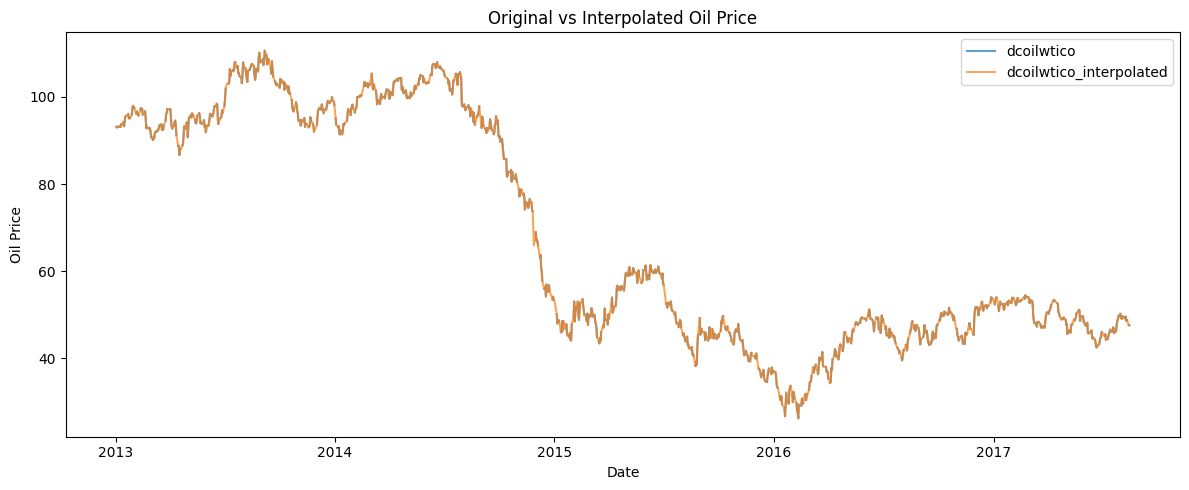

In [25]:
plt.figure(figsize=(12, 5))
for name, group in q4b_df.groupby("series"):
    plt.plot(group["date"], group["value"], label=name, alpha=0.7)

plt.xlabel("Date")
plt.ylabel("Oil Price")
plt.title("Original vs Interpolated Oil Price")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# 1. Left join the interpolated oil feature onto merged_df and store the result back in merged_df.
# 2. Keep merged_df for later questions.

merged_df = merged_df.merge(
    oil_daily[["date", "dcoilwtico_interpolated"]],
    on="date",
    how="left"
)


In [28]:
# Using q5a_df, create q5b_input_df for the oil-vs-sales correlation calculation.
# Remove rows with missing values if needed.

q5b_input_df = q5a_df[["dcoilwtico_interpolated", "sales"]].dropna()


In [30]:
# Using q5a_df, create q5c_input_df for the oil-vs-transactions correlation calculation.
# Remove rows with missing values if needed.

q5c_input_df = q5a_df[["dcoilwtico_interpolated", "transactions"]].dropna()


In [32]:
# Using merged_df, create q6a_input_df with the columns needed for the per-family correlation calculation.
# Keep only rows with non-null sales if needed.

q6a_input_df = merged_df[["family", "sales", "dcoilwtico_interpolated"]].dropna(subset=["sales"])


## 3. Categorical encoding

In [34]:
def one_hot_encoder(df, nan_as_category=True) -> Tuple[pd.DataFrame, List[str]]:
    original_columns = list(df.columns)
    categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
    encoded_df = pd.get_dummies(df.copy(), columns=categorical_columns, dummy_na=nan_as_category)
    encoded_df = encoded_df.rename(columns=lambda col: col.replace(" ", "_"))
    original_renamed = [col.replace(" ", "_") for col in original_columns]
    new_columns = [col for col in encoded_df.columns if col not in original_renamed]
    return encoded_df, new_columns
    # One hot encode all object/category columns.
    # Leave non-categorical columns unchanged.
    # If nan_as_category=True, include missing-value dummy columns.
    # Replace spaces in output column names with underscores.
    # Return the encoded dataframe and the list of newly created columns in output order.


## 4. Leak-free validation split
The last labeled block (2017-07-17 to 2017-07-31), right before the unlabeled test period, is held out for validation so the model never sees future data.

In [36]:
val_start = "2017-07-17"
val_end = "2017-07-31"

X_train = train[train["date"] < val_start].drop(columns=["sales"])
y_train = train[train["date"] < val_start]["sales"]

X_val = train[(train["date"] >= val_start) & (train["date"] <= val_end)].drop(columns=["sales"])
y_val = train[(train["date"] >= val_start) & (train["date"] <= val_end)]["sales"]

X_test = test.drop(columns=["sales"], errors="ignore")

## 5. Gradient-boosting baselines
LightGBM, CatBoost and XGBoost with default-style settings, scored by validation RMSLE.

In [37]:
import lightgbm as lgb

In [38]:
# Process your data to the appropriate dtypes, vars, etc.
drop_cols = ["date", "id"]
feature_cols = [c for c in X_train.columns if c not in drop_cols]

In [39]:
# Use the lgb.Dataset method to intialize your dataset iterables.

# 1. Make one for the train set:
lgb_train = lgb.Dataset(X_train[feature_cols], label=y_train)
# 2. Make another for the val set you defined in Q8A:
lgb_val = lgb.Dataset(X_val[feature_cols], label=y_val, reference=lgb_train)

In [40]:
# Fill the dict with appropriate params:
lgb_params = {'num_leaves': 31,
              'learning_rate': 0.1,
              'feature_fraction': 0.8,
              'max_depth': -1,
              'verbose': -1,
              'num_boost_round': 500,
              'early_stopping_rounds': 50,
              'nthread': -1}

In [41]:
# Complete the model initialization/train params)
model = lgb.train(lgb_params, lgb_train, valid_sets=[lgb_val],
                  num_boost_round=lgb_params['num_boost_round'],
                  callbacks=[lgb.early_stopping(lgb_params['early_stopping_rounds']),
                             lgb.log_evaluation(lgb_params['verbose'])])

Training until validation scores don't improve for 50 rounds


In [42]:
# 1. Predict the sales value on your val set using the best_iteration from the trained LGBM
# 2. Compute and print the RMSLE on this val set.
val_preds = model.predict(X_val[feature_cols], num_iteration=model.best_iteration)
val_preds = np.clip(val_preds, 0, None)
print("LightGBM Validation RMSLE:", helper.rmsle(y_val, val_preds))

LightGBM Validation RMSLE: 1.1625225384497815


In [43]:
# 1. Pre-process your test set to the appropriate format.
# 2. Predict on the test set.
test_preds = model.predict(X_test[feature_cols], num_iteration=model.best_iteration)
test_preds = np.clip(test_preds, 0, None)

In [45]:
from catboost import Pool, CatBoostRegressor

In [46]:
# Fill out missing params for catboost appropriately here:
catboost_params = {
    'iterations': 200,           # Number of boosting rounds
    'learning_rate': 0.1,        # Learning rate for gradient boosting
    'depth': 6,                   # Depth of each tree
    'loss_function': 'RMSE',      # Loss function (Root Mean Squared Error for regression)
    'eval_metric': 'RMSE',        # Evaluation metric
    'random_seed': 42,            # Ensures reproducibility
    'early_stopping_rounds': 50,  # Stops training if no improvement after 50 rounds
    'verbose': 100                # Prints training progress every 100 rounds
}

In [47]:
# 1. Define the model
model_cb = CatBoostRegressor(**catboost_params)
# 2. Fit
model_cb.fit(X_train[feature_cols], y_train,
             eval_set=(X_val[feature_cols], y_val))

0:	learn: 1019.5397476	test: 1187.2823128	best: 1187.2823128 (0)	total: 179ms	remaining: 35.6s
100:	learn: 388.8967711	test: 334.9950277	best: 334.9950277 (100)	total: 11.6s	remaining: 11.3s
199:	learn: 358.6706399	test: 296.5841100	best: 296.5841100 (199)	total: 23s	remaining: 0us

bestTest = 296.58411
bestIteration = 199



CatBoostRegressor(depth=6, early_stopping_rounds=50, eval_metric='RMSE', iterations=200, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=100)

In [48]:
# 3. Preprocess your test data appropriately

# 4. Make Predictions

val_preds_cb = model_cb.predict(X_val[feature_cols])
val_preds_cb = np.clip(val_preds_cb, 0, None)
print("CatBoost Validation RMSLE:", helper.rmsle(y_val, val_preds_cb))

CatBoost Validation RMSLE: 1.4339363550935667


In [49]:
# 1. Use your fitted CatBoost model to generate test predictions.

test_preds_cb = model_cb.predict(X_test[feature_cols])
test_preds_cb = np.clip(test_preds_cb, 0, None)

In [51]:
from xgboost import XGBRegressor

In [52]:
# 1. Initialize model with random state = 42 to be consistent with CatBoost

model_xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    tree_method='hist',
    verbosity=0
)
# 2. Fit
model_xgb.fit(X_train[feature_cols], y_train,
              eval_set=[(X_val[feature_cols], y_val)],
              verbose=100)

[0]	validation_0-rmse:1196.94231
[100]	validation_0-rmse:339.55985
[199]	validation_0-rmse:309.48451


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [53]:
# 3. Make Predictions.
val_preds_xgb = model_xgb.predict(X_val[feature_cols])
val_preds_xgb = np.clip(val_preds_xgb, 0, None)
print("XGBoost Validation RMSLE:", helper.rmsle(y_val, val_preds_xgb))

XGBoost Validation RMSLE: 1.4527683


In [54]:
# 1. Use your fitted XGBoost model to generate test predictions.

test_preds_xgb = model_xgb.predict(X_test[feature_cols])
test_preds_xgb = np.clip(test_preds_xgb, 0, None)

## 6. Hyperparameter tuning with Optuna
10 trials per model, minimizing validation RMSLE.

In [56]:
import optuna
import time
import gc

In [57]:
def objective_lgb(trial):
    # 1. Define the parameter search space
    params = {
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'verbose': -1,
        'nthread': -1,
    }
    # 2. Create datasets (train, val) for LightGBM
    lgb_train_t = lgb.Dataset(X_train[feature_cols], label=y_train)
    lgb_val_t = lgb.Dataset(X_val[feature_cols], label=y_val, reference=lgb_train_t)

    # 3. Train the model
    model_t = lgb.train(params, lgb_train_t, valid_sets=[lgb_val_t],
                        num_boost_round=500,
                        callbacks=[lgb.early_stopping(50), lgb.log_evaluation(-1)])

    # 4. Evaluate on the validation set
    val_preds_t = model_t.predict(X_val[feature_cols], num_iteration=model_t.best_iteration)
    val_preds_t = np.clip(val_preds_t, 0, None)
    
    # 5. Return the metric score
    score = helper.rmsle(y_val, val_preds_t)
    del model_t, lgb_train_t, lgb_val_t
    gc.collect()
    return score

# Create Optuna study to minimize the objective function

start = time.time()
# 1. Create the optuna study and specify appropriate direction
study_lgb = optuna.create_study(direction='minimize')
# 2. Optimize (pay attention to recommended trials; 50 takes too long)
study_lgb.optimize(objective_lgb, n_trials=10)
# 3. Get the best parameters
best_params_lgb = study_lgb.best_params
# 4. Print them.
print("Best parameters:", best_params_lgb)
print("Took:", time.time() - start, "seconds")


Training until validation scores don't improve for 50 rounds


Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 172153
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 57693.1


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 54758.1


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[493]	valid_0's l2: 53449


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[355]	valid_0's l2: 50438.2


Training until validation scores don't improve for 50 rounds


Did not meet early stopping. Best iteration is:
[499]	valid_0's l2: 59601.7
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 70039.8


Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 81307.2


Training until validation scores don't improve for 50 rounds


Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 118412
Training until validation scores don't improve for 50 rounds


Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 53557.5
Best parameters: {'num_leaves': 35, 'learning_rate': 0.2782915774835796, 'feature_fraction': 0.8257075126352396, 'max_depth': 11, 'min_child_samples': 33}
Took: 167.5435290336609 seconds


In [58]:
# 1. Generate tuned test predictions for LightGBM.
best_params_lgb['verbose'] = -1
best_params_lgb['nthread'] = -1

lgb_train_f = lgb.Dataset(X_train[feature_cols], label=y_train)
lgb_val_f = lgb.Dataset(X_val[feature_cols], label=y_val, reference=lgb_train_f)

model_lgb_tuned = lgb.train(best_params_lgb, lgb_train_f, valid_sets=[lgb_val_f],
                            num_boost_round=500,
                            callbacks=[lgb.early_stopping(50), lgb.log_evaluation(-1)])

test_preds_lgb_t = model_lgb_tuned.predict(X_test[feature_cols], num_iteration=model_lgb_tuned.best_iteration)
test_preds_lgb_t = np.clip(test_preds_lgb_t, 0, None)
del model_lgb_tuned, lgb_train_f, lgb_val_f
gc.collect()

Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 53557.5


12

In [59]:
# Do the same Optuna-based tuning process for CatBoost.
# Define the CatBoost objective, run the study, and get the best parameters.
def objective_cb(trial):
    params = {
        'iterations': 500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'depth': trial.suggest_int('depth', 4, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
        'random_seed': 42,
        'early_stopping_rounds': 50,
        'verbose': 0,
        'loss_function': 'RMSE',
    }

    model_t = CatBoostRegressor(**params)
    model_t.fit(X_train[feature_cols], y_train,
                eval_set=(X_val[feature_cols], y_val))

    val_preds_t = model_t.predict(X_val[feature_cols])
    val_preds_t = np.clip(val_preds_t, 0, None)
    score = helper.rmsle(y_val, val_preds_t)
    del model_t
    gc.collect()
    return score

start = time.time()
study_cb = optuna.create_study(direction='minimize')
study_cb.optimize(objective_cb, n_trials=10)
best_params_cb = study_cb.best_params
print("Best parameters:", best_params_cb)
print("Took:", time.time() - start, "seconds")

Best parameters: {'learning_rate': 0.1632926256944901, 'depth': 10, 'l2_leaf_reg': 1.1770193742995323}
Took: 840.9100332260132 seconds


In [60]:
# 1. Generate tuned test predictions for CatBoost.
best_params_cb['iterations'] = 500
best_params_cb['random_seed'] = 42
best_params_cb['early_stopping_rounds'] = 50
best_params_cb['verbose'] = 0
best_params_cb['loss_function'] = 'RMSE'

model_cb_tuned = CatBoostRegressor(**best_params_cb)
model_cb_tuned.fit(X_train[feature_cols], y_train,
                   eval_set=(X_val[feature_cols], y_val))

test_preds_cb_t = model_cb_tuned.predict(X_test[feature_cols])
test_preds_cb_t = np.clip(test_preds_cb_t, 0, None)

In [62]:
# Do the same Optuna-based tuning process for XGBoost.
# Define the XGBoost objective, run the study, and get the best parameters.
def objective_xgb(trial):
    params = {
        'n_estimators': 500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'random_state': 42,
        'early_stopping_rounds': 50,
        'tree_method': 'hist',
        'verbosity': 0,
    }

    model_t = XGBRegressor(**params)
    model_t.fit(X_train[feature_cols], y_train,
                eval_set=[(X_val[feature_cols], y_val)],
                verbose=False)

    val_preds_t = model_t.predict(X_val[feature_cols])
    val_preds_t = np.clip(val_preds_t, 0, None)
    score = helper.rmsle(y_val, val_preds_t)
    del model_t
    gc.collect()
    return score

start = time.time()
study_xgb = optuna.create_study(direction='minimize')
study_xgb.optimize(objective_xgb, n_trials=10)
best_params_xgb = study_xgb.best_params
print("Best parameters:", best_params_xgb)
print("Took:", time.time() - start, "seconds")

Best parameters: {'learning_rate': 0.2876676750323111, 'max_depth': 10, 'min_child_weight': 6, 'subsample': 0.6789470925621677, 'colsample_bytree': 0.8350891789966822}
Took: 686.3651189804077 seconds


In [63]:
# 1. Generate tuned test predictions for XGBoost.
best_params_xgb['n_estimators'] = 500
best_params_xgb['random_state'] = 42
best_params_xgb['early_stopping_rounds'] = 50
best_params_xgb['tree_method'] = 'hist'
best_params_xgb['verbosity'] = 0

model_xgb_tuned = XGBRegressor(**best_params_xgb)
model_xgb_tuned.fit(X_train[feature_cols], y_train,
                    eval_set=[(X_val[feature_cols], y_val)],
                    verbose=False)

test_preds_xgb_t = model_xgb_tuned.predict(X_test[feature_cols])
test_preds_xgb_t = np.clip(test_preds_xgb_t, 0, None)

del model_xgb_tuned
gc.collect()

53

## 7. Linear baseline: Ridge regression

In [ ]:
# 1. Choose one new model that is different from LightGBM, CatBoost, and XGBoost.
# 2. Train it using the validation split from Q8A.
# 3. Evaluate it on the validation set.
# 4. Keep the fitted model and any preprocessing objects for later use.
from sklearn.linear_model import Ridge

new_model_name = "Ridge Regression"

# Simple numeric features only (matches the script that generated the CSV)
simple_features = ['store_nbr', 'onpromotion', 'year', 'month', 'day', 'dayofweek']

# Add time features if not already present
for df in [X_train, X_val, X_test]:
    df['year'] = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['day'] = df['date'].dt.day
    df['dayofweek'] = df['date'].dt.dayofweek

new_model = Ridge(alpha=1.0)
new_model.fit(X_train[simple_features].fillna(0).astype(np.float32), y_train)

val_preds_new = new_model.predict(X_val[simple_features].fillna(0).astype(np.float32))
val_preds_new = np.clip(val_preds_new, 0, None)
new_model_val_rmsle = helper.rmsle(y_val, val_preds_new)
print(f"{new_model_name} Validation RMSLE:", new_model_val_rmsle)

In [ ]:
# 1. Generate test predictions using your fitted new model.
test_preds_new = new_model.predict(X_test[simple_features].fillna(0).astype(np.float32))
test_preds_new = np.clip(test_preds_new, 0, None)